# Desarrollo y Pruebas (Práctica 1) + Código Base (Práctica 2)

## Práctica 1

### Implementación

Perceptrón con función de activación **sigmoide**, costo de **entropía cruzada** y entrenamiento por **gradiente descendente**. Las entradas se expanden a un polinomio de grado 2 y se normalizan (z-score) antes de entrenar.

**Funciones auxiliares**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def func_costo(W_1d, Xa, Y):
    # Costo (entropía cruzada) y gradiente del perceptrón con sigmoide
    W = W_1d.reshape(-1, 1)
    Z = Xa @ W
    Yg = 1.0 / (1.0 + np.exp(-Z))              # Función sigmoide (salida entre 0 y 1)
    n = Xa.shape[0]
    eps = np.finfo(float).eps
    Yg = np.clip(Yg, eps, 1.0 - eps)           # Evita log(0)
    J = np.sum(-Y * np.log(Yg) - (1.0 - Y) * np.log(1.0 - Yg)) / n
    E = Yg - Y                                 # Error
    dJdW = (E.T @ Xa).T / n                    # Gradiente
    return J, dJdW.flatten()

def func_polinomio(X, ngrado):
    # Construye la matriz [1 x1 x2 x1x2 x1^2 x2^2 ...] hasta el grado indicado
    m, nvar = X.shape
    Xp = np.ones((m, 1))
    coef = np.zeros((1, nvar))
    for g in range(1, ngrado + 1):
        # Exponentes de los términos cruzados de este grado
        if g - 1 >= 1:
            Atemp = np.hstack((np.arange(g - 1, 0, -1).reshape(-1, 1), np.arange(1, g).reshape(-1, 1)))
        else:
            Atemp = np.empty((0, 2))
        A = np.empty((0, nvar))
        for i in range(nvar - 1):
            for j in range(i + 1, nvar):
                if Atemp.shape[0] > 0:
                    Btemp = np.zeros((g - 1, nvar))
                    Btemp[:, i] = Atemp[:, 0]
                    Btemp[:, j] = Atemp[:, 1]
                    A = np.vstack((A, Btemp))
        A = np.vstack((A, g * np.eye(nvar)))   # Términos puros: x1^g, x2^g
        # Eleva cada variable a su exponente y agrega la columna
        for k in range(A.shape[0]):
            temp = np.ones((m, 1))
            for j in range(nvar):
                temp = temp * (X[:, j].reshape(-1, 1) ** A[k, j])
            Xp = np.hstack((Xp, temp))
        coef = np.vstack((coef, A))
    return Xp, coef.T

def entrenar_gd(Xa, Y, eta, epocas):
    # Gradiente descendente: W <- W - eta * gradiente
    W = np.zeros(Xa.shape[1])
    J_history = np.zeros(epocas)
    for i in range(epocas):
        J_history[i], dJdW = func_costo(W, Xa, Y)
        W = W - eta * dJdW
    return W.reshape(-1, 1), J_history

def predecir(X, W, grado, mu, sigma):
    # Aplica polinomio + normalización con mu/sigma del entrenamiento y la sigmoide
    Xp, _ = func_polinomio(X, grado)
    Xp[:, 1:] = (Xp[:, 1:] - mu) / (sigma + 1e-8)
    prob = 1.0 / (1.0 + np.exp(-(Xp @ W)))
    return prob, np.round(prob).astype(int)     # Probabilidad y clase (0 o 1)

def metricas(Y, Yg):
    # Matriz de confusión y métricas de rendimiento
    y, yg = Y.ravel().astype(int), Yg.ravel().astype(int)
    TP = np.sum((y == 1) & (yg == 1)); TN = np.sum((y == 0) & (yg == 0))
    FP = np.sum((y == 0) & (yg == 1)); FN = np.sum((y == 1) & (yg == 0))
    print(f"TP = {TP} | TN = {TN} | FP = {FP} | FN = {FN}")
    print(f"Accuracy = {(TP + TN) / len(y):.4f} | Precision = {TP / max(TP + FP, 1):.4f} | Recall = {TP / max(TP + FN, 1):.4f}")

def graficar_frontera(data, W, grado, mu, sigma, x1_lim, x2_lim, titulo, ax=None):
    # Dibuja los datos y la región que el modelo asigna a cada clase
    ax = ax or plt.gca()
    x1, x2 = np.meshgrid(np.linspace(*x1_lim, 300), np.linspace(*x2_lim, 300))
    _, clase = predecir(np.column_stack((x1.ravel(), x2.ravel())), W, grado, mu, sigma)
    ax.contourf(x1, x2, clase.reshape(x1.shape), alpha=0.15, cmap="jet")
    G0, G1 = data[data[:, 2] == 0], data[data[:, 2] == 1]
    ax.plot(G0[:, 0], G0[:, 1], "bo", label="Clase 0")
    ax.plot(G1[:, 0], G1[:, 1], "rx", label="Clase 1")
    ax.set(xlabel="X1", ylabel="X2", title=titulo); ax.legend()

**Carga, polinomio y normalización**

In [2]:
data1 = np.loadtxt("data1.txt", delimiter=",")
X1, Y1 = data1[:, 0:2], data1[:, 2].reshape(-1, 1)

grado1 = 2
Xa1, _ = func_polinomio(X1, grado1)

# Normalización z-score (sin la columna de unos)
mu1, sigma1 = Xa1[:, 1:].mean(axis=0), Xa1[:, 1:].std(axis=0)
Xa1[:, 1:] = (Xa1[:, 1:] - mu1) / (sigma1 + 1e-8)

print(f"Datos: {len(Y1)} | Clase 0: {int((Y1 == 0).sum())} | Clase 1: {int((Y1 == 1).sum())}")
print(f"Costo inicial (W = 0): {func_costo(np.zeros(Xa1.shape[1]), Xa1, Y1)[0]:.4f}")

Datos: 100 | Clase 0: 40 | Clase 1: 60
Costo inicial (W = 0): 0.6931


**Entrenamiento** (η = 0.5, 10 000 épocas)

In [3]:
eta, epocas = 0.5, 10000
W1, J1 = entrenar_gd(Xa1, Y1, eta, epocas)
print(f"Costo final: {J1[-1]:.4f}")
print("Pesos:", W1.ravel().round(4))

Costo final: 0.0427
Pesos: [ 9.15    6.6135  4.3451 19.2328 -7.0689 -4.2874]


### Resultados

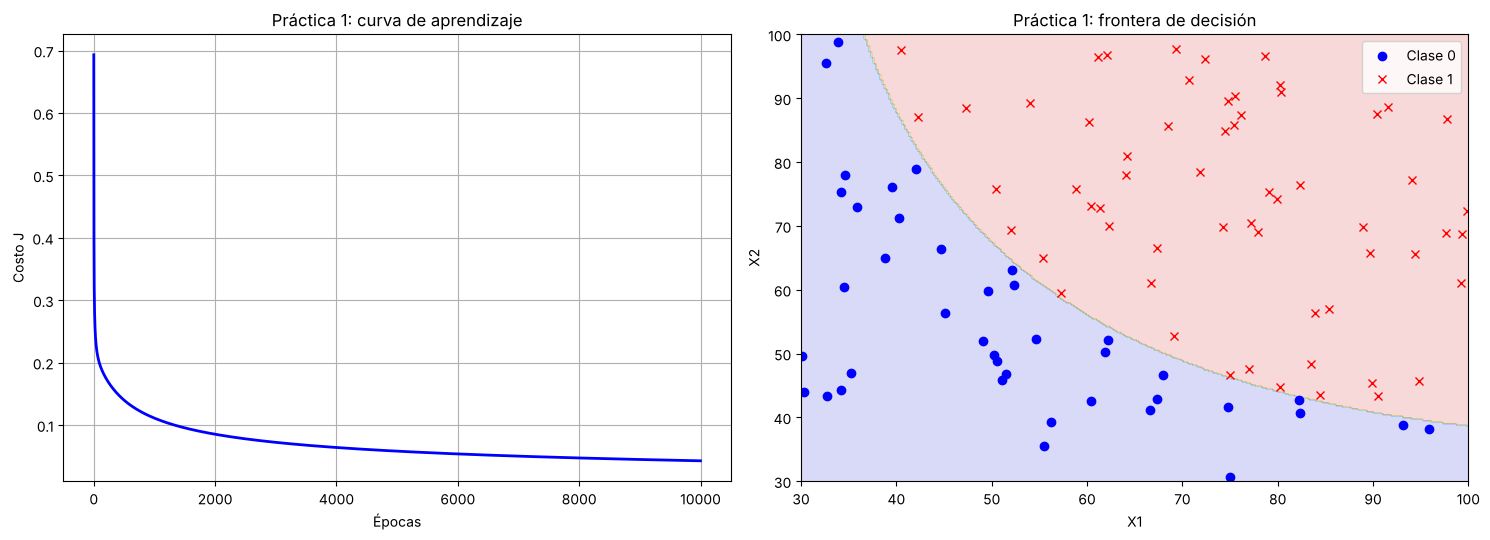

TP = 60 | TN = 40 | FP = 0 | FN = 0
Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
axs[0].plot(J1, "b-", lw=2)
axs[0].set(xlabel="Épocas", ylabel="Costo J", title="Práctica 1: curva de aprendizaje"); axs[0].grid(True)
graficar_frontera(data1, W1, grado1, mu1, sigma1, (30, 100), (30, 100), "Práctica 1: frontera de decisión", axs[1])
plt.tight_layout(); plt.show()

_, Yg1 = predecir(X1, W1, grado1, mu1, sigma1)
metricas(Y1, Yg1)

**Análisis**
- El costo baja de 0.693 a 0.043. Cae rápido en las primeras ~200 épocas y luego sigue bajando despacio: como las dos clases se pueden separar por completo, el modelo sigue "afinando" los pesos.
- La frontera de grado 2 es una curva que separa todos los puntos: **0 falsos positivos y 0 falsos negativos** (accuracy, precision y recall = 1.00).
- Estas métricas se calcularon con los mismos datos de entrenamiento, así que miden qué tan bien se ajustó el modelo, no qué tan bien predice datos nuevos.

## Práctica 2

### Implementación (entrenamiento)

Mismo modelo y funciones que en la Práctica 1, ahora con `data2.txt`.

In [5]:
data2 = np.loadtxt("data2.txt", delimiter=",")
X2, Y2 = data2[:, 0:2], data2[:, 2].reshape(-1, 1)

grado2 = 2
Xa2, _ = func_polinomio(X2, grado2)

# Normalización z-score; mu2 y sigma2 se guardan para evaluar datos nuevos
mu2, sigma2 = Xa2[:, 1:].mean(axis=0), Xa2[:, 1:].std(axis=0)
Xa2[:, 1:] = (Xa2[:, 1:] - mu2) / (sigma2 + 1e-8)

# Entrenamiento por gradiente descendente
W2, J2 = entrenar_gd(Xa2, Y2, eta=0.5, epocas=10000)
print(f"Costo final: {J2[-1]:.4f}")
print("Pesos:", W2.ravel().round(4))

_, Yg2 = predecir(X2, W2, grado2, mu2, sigma2)
metricas(Y2, Yg2)

Costo final: 0.3481
Pesos: [-0.2385  1.606   2.1562 -1.6804 -2.9764 -3.3496]
TP = 50 | TN = 51 | FP = 9 | FN = 8
Accuracy = 0.8559 | Precision = 0.8475 | Recall = 0.8621


### Clasificación de nuevos puntos con los pesos obtenidos

Se evalúa el arreglo solicitado con los pesos `W2`. Cada punto pasa por el mismo polinomio y la misma normalización (`mu2`, `sigma2`) del entrenamiento; si la probabilidad es ≥ 0.5 se asigna la clase 1, si no, la clase 0.

In [6]:
# Arreglo solicitado
X_nuevos = np.array([[-1,    1   ],
                     [ 0,    2   ],
                     [ 0,    1   ],
                     [ 0.5,  0.5 ],
                     [ 0.75, 0.75],
                     [ 1,    1   ],
                     [ 2,    3   ],
                     [ 2,   -1   ]])

prob_nuevos, clase_nuevos = predecir(X_nuevos, W2, grado2, mu2, sigma2)

import pandas as pd
tabla_nuevos = pd.DataFrame({"X1": X_nuevos[:, 0], "X2": X_nuevos[:, 1],
                             "Probabilidad clase 1": prob_nuevos.ravel().round(4),
                             "Clase": clase_nuevos.ravel()})
tabla_nuevos

,X1,X2,Probabilidad clase 1,Clase
0,-1.00,1.00,0.0000,0
1,0.00,2.00,0.0000,0
2,0.00,1.00,0.0768,0
3,0.50,0.50,0.7371,1
4,0.75,0.75,0.0010,0
5,1.00,1.00,0.0000,0
6,2.00,3.00,0.0000,0
7,2.00,-1.00,0.0000,0


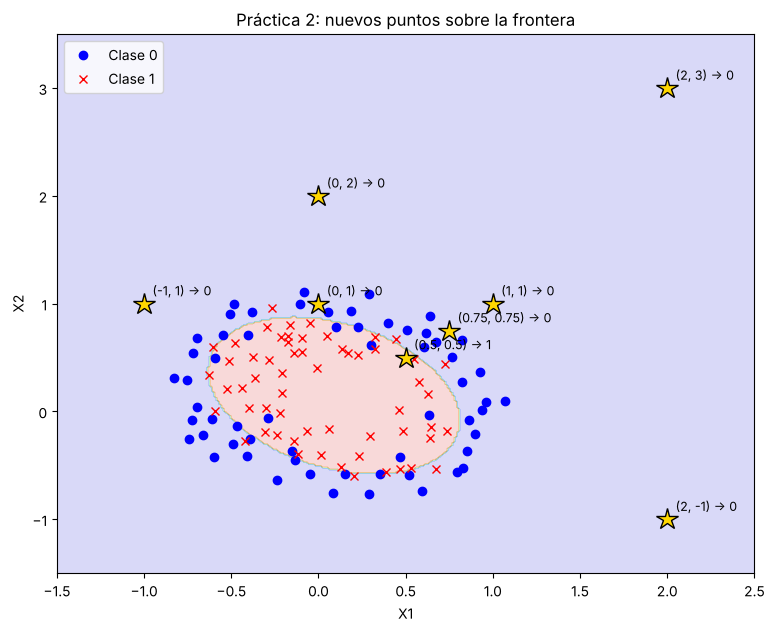

In [7]:
plt.figure(figsize=(9, 7))
graficar_frontera(data2, W2, grado2, mu2, sigma2, (-1.5, 2.5), (-1.5, 3.5), "Práctica 2: nuevos puntos sobre la frontera")
for (x1, x2), cl in zip(X_nuevos, clase_nuevos.ravel()):
    plt.plot(x1, x2, "k*", ms=16, mfc="gold")
    plt.annotate(f"({x1:g}, {x2:g}) → {cl}", (x1, x2), xytext=(6, 6), textcoords="offset points", fontsize=9)
plt.show()

**Análisis**
- Solo **(0.5, 0.5)** se clasifica como clase 1 (probabilidad 0.74), porque cae dentro de la elipse donde están los puntos de clase 1.
- **(0, 1)** queda cerca del borde, pero del lado de afuera (0.08), por lo que es clase 0. Los demás puntos quedan lejos de la zona de clase 1 y su probabilidad es prácticamente 0.
- (−1, 1), (0, 2), (2, 3) y (2, −1) están fuera del rango de los datos de entrenamiento, así que el modelo está extrapolando: su resultado es menos confiable.
- Con grado 2 el entrenamiento llega a un costo de 0.348 y una accuracy de 0.856 (9 FP, 8 FN). La elipse no alcanza a seguir bien el borde irregular de los datos.

## Conclusión personal

En la Práctica 1 vi que el perceptrón con sigmoide separa muy bien dos clases cuando la frontera es sencilla. En la Práctica 2 los datos forman un círculo, y aun así el mismo modelo funciona porque se le agregan los términos del polinomio. También aprendí que, para clasificar puntos nuevos, hay que aplicarles exactamente la misma transformación que a los datos de entrenamiento (polinomio y normalización con la misma media y desviación); si no, los pesos no sirven. Por último, un punto fuera del rango de los datos siempre se va a clasificar, pero eso no significa que el resultado sea confiable.